# Figure 1 -- publication assembly

Rebuilds `Fig1_alt.png` **entirely in code**, at Nature Genetics figure spec
(180 x 183 mm, sans-serif 5.5-6.5 pt, rules <= 0.4 pt, bold lower-case panel
letters). The hand-assembled Inkscape file `Figure1.svg` is only the visual
reference.

**Layout.** The hand-drawn schematic that used to be panel A of `Fig1_alt.png`
is dropped and the surviving panels are promoted:

| new | old | content |
|-----|-----|---------|
| **a** | B | *SRSF3* read-count matrix, with the two-column GTEx tissue key beside it |
| **b** | C | the ten Torino factor tracks |
| **c** | D | per-tissue stacked loadings |
| **d** | E | isoform identification: factor tracks + Torino models + Gencode models |

Two things tie the layout together:

* **Panels b and d share a column.** `panel_B`'s ten tracks are placed at exactly
  the x-position, width, row height, `ylim` and line width of the factor tracks
  inside panel d, so the reader sees the same object twice at the same scale.
  Both read those numbers from `D_COL_TRACK` / `D_ROW_H` / `TRACK_YMAX`.
* **The canvas is planned in millimetres**, top-left origin, via the `rect()`
  helper in `build_figure` -- so panel positions can be reasoned about directly
  in page units rather than in figure fractions.

**Source of the plotting logic:** `Figure1.ipynb` / `Figure1_plot_helpers.py`.
Those helpers each build their own `fig, axes`, so every panel is re-implemented
below to draw into axes this notebook positions itself.


## Setup and shared style

In [1]:
import os
import pickle

import numpy as np

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import FancyBboxPatch, Rectangle
import seaborn as sns

# ── Figure canvas ──────────────────────────────────────────────────────
MM = 1 / 25.4
FIG_W_MM = 180.0          # Nature Genetics double-column
FIG_H_MM = 183.0

# ── Typography (Nature Genetics: sans-serif, 5-7 pt, no rules heavier
#    than 0.5 pt, panel letters bold lower-case) ─────────────────────────
FS_BASE = 6.0             # axis labels / tick labels
FS_TITLE = 6.5            # panel titles, Gencode captions
FS_GROUP = 6.5            # bold group titles inside panel D
FS_SMALL = 5.5            # factor labels, legend entries
FS_PANEL = 8.0            # panel letters
PANEL_LETTERS = 'abcd'    # -> 'ABCD' for journals that want upper case

# ── Factor tracks: one shape, used by panels B and D alike ─────────────
TRACK_YMAX = 1.30         # ylim top (headroom for panel D's junction arcs)
TRACK_LW = 1.0

mpl.rcParams.update({
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
    "font.size": FS_BASE,
    "axes.titlesize": FS_TITLE,
    "axes.labelsize": FS_BASE,
    "xtick.labelsize": FS_BASE,
    "ytick.labelsize": FS_BASE,
    "axes.labelpad": 1.5,
    "axes.linewidth": 0.4,
    "xtick.major.width": 0.4,
    "ytick.major.width": 0.4,
    "xtick.minor.width": 0.3,
    "ytick.minor.width": 0.3,
    "xtick.major.size": 1.6,
    "ytick.major.size": 1.6,
    "xtick.major.pad": 1.5,
    "ytick.major.pad": 1.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 150,
    "savefig.dpi": 400,
    # Keep the exact 180 x 183 mm page. A "tight" bbox would both re-crop the
    # canvas and drop panel D's container, whose patches live on the figure
    # rather than in an axes and so are invisible to the tight-bbox pass.
    "savefig.bbox": "standard",
})

# The inline backend crops with bbox_inches='tight' by default; turn that off so
# the notebook preview matches the exported file.
try:
    get_ipython().run_line_magic(
        'config', "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")
except NameError:
    pass

# ── Shared colours ─────────────────────────────────────────────────────
TAB10 = sns.color_palette("tab10")     # factor k -> TAB10[k - 1]
C_EXON = 'midnightblue'                # Torino isoform exons
C_HIGHLIGHT = 'red'                    # distinguishing exon(s)
C_GENCODE = 'black'                    # Gencode models
C_BOX_OUTER = '#cccccc'                # panel D container
C_BOX_INNER = 'white'

## Data

Pre-computed by `Figure1_helpers.run_all()`; rerun that to refresh `figure_data/`.

In [2]:
data_dir = 'figure_data'
_keys = ['data', 'tissues_display', 'colors_list_display',
         'EF_factors', 'K_factors',
         'EL_to_plot', 'human_metadata_h', 'colores_h',
         'colors_list_h', 'n_tissues_h',
         'human_iso', 'gencode_iso']
_d = {}
for _k in _keys:
    with open(os.path.join(data_dir, f'{_k}.pkl'), 'rb') as _f:
        _d[_k] = pickle.load(_f)
globals().update(_d)

GENE = 'SRSF3'

# Factor tracks are normalised once: divide by the 99th percentile, clip at 1.
EF_NORM = np.minimum(EF_factors / EF_factors.quantile(0.99, axis=0), 1.0)
EF_COORDS = np.array([int(c.split(':')[1]) for c in EF_NORM.index])

# Exon tables restricted to the gene of interest.
TORINO_EXONS = human_iso.loc[human_iso.gene_id == GENE].copy()
GENCODE_EXONS = gencode_iso.loc[gencode_iso.gene_id == GENE].copy()

## Panel a -- *SRSF3* read-count matrix

In [3]:
SIDEBAR_PROPORTIONAL = False   # True -> strip blocks scale with sample counts


def panel_A(ax_side, ax_heat, cax):
    """SRSF3 read-count matrix with a GTEx tissue colour strip."""
    m = np.log10(data.values + 1)

    im = ax_heat.imshow(m, cmap='binary', aspect='auto',
                        interpolation='nearest', rasterized=True)
    ax_heat.set_xticks([])
    ax_heat.set_yticks([])
    for s in ax_heat.spines.values():
        s.set_visible(False)
    ax_heat.set_xlabel('Base-pairs', fontsize=FS_BASE)
    ax_heat.set_title(f'$\\mathit{{{GENE}}}$ count matrix', fontsize=FS_TITLE, pad=3)

    # ── Colour bar: linear in log10(counts + 1), labelled in raw counts ──
    ticks_major = np.log10(np.array([1, 11, 101]))
    ticks_minor = np.log10(np.array(
        [2, 3, 4, 5, 6, 7, 8, 9] + list(range(21, 100, 10)) + list(range(201, 1000, 100))))
    cb = plt.colorbar(im, cax=cax)
    cb.set_ticks(ticks_major)
    cb.set_ticklabels(['0', '10', '100'])
    cb.ax.yaxis.set_ticks(ticks_minor, minor=True)
    cb.ax.tick_params(which='major', labelsize=FS_BASE, length=1.6, width=0.4, pad=1.2)
    cb.ax.tick_params(which='minor', length=0.7, width=0.25)
    cb.set_label('read counts', fontsize=FS_BASE, labelpad=1.5)
    cb.outline.set_linewidth(0.3)

    # ── Tissue colour strip ────────────────────────────────────────────
    # Fig1_alt draws one *equal-sized* block per tissue, so the strip is a key
    # rather than a row annotation. Set SIDEBAR_PROPORTIONAL = True to size each
    # block by its sample count, which makes it line up with the heatmap rows.
    n = len(tissues_display)
    if SIDEBAR_PROPORTIONAL:
        order = human_metadata_h.loc[data.index].tissue_id
        sizes = np.array([(order == t).sum() for t in dict.fromkeys(order)], float)
    else:
        sizes = np.ones(n)
    edges = np.concatenate([[0], np.cumsum(sizes)])
    total = edges[-1]
    gap = total * 0.004
    ax_side.set_xlim(0, 1)
    ax_side.set_ylim(0, total)
    for i, col in enumerate(colors_list_display):
        lo, hi = total - edges[i + 1] + gap, total - edges[i] - gap
        ax_side.add_patch(Rectangle((0, lo), 1, max(hi - lo, 0),
                                    facecolor=col, edgecolor='none'))
    ax_side.set_xticks([])
    ax_side.set_yticks([])
    for s in ax_side.spines.values():
        s.set_visible(False)
    ax_side.set_ylabel('GTEx samples', fontsize=FS_BASE, labelpad=2.5)

## Panel b -- factor tracks

In [4]:
def panel_B(axes):
    """The ten SRSF3 factors, one track per row.

    Drawn with the same ylim, line width and axes size as the tracks in panel D,
    and placed over panel D's track column, so the two read as one object.
    """
    xlim = (EF_COORDS[0], EF_COORDS[-1])
    for i, ax in enumerate(axes):
        y = EF_NORM[f'factor{i + 1}'].values
        col = TAB10[i]
        ax.fill_between(EF_COORDS, 0, y, color=col, alpha=0.30, lw=0)
        ax.plot(EF_COORDS, y, color=col, alpha=0.90, lw=TRACK_LW)
        ax.set_xlim(xlim)
        ax.set_ylim(0, TRACK_YMAX)
        ax.set_xticks([])
        ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)
        ax.text(1.02, 0.02, f'Factor {i + 1}', transform=ax.transAxes,
                fontsize=FS_SMALL, va='bottom', ha='left')
    axes[-1].set_xlabel('Base-pairs', fontsize=FS_BASE)

## Panel c -- per-tissue stacked loadings

In [5]:
def panel_C(axes_bars, axes_blocks, ax_axis):
    """Per-tissue stacked loadings, one row per GTEx sample."""
    samples = human_metadata_h.loc[EL_to_plot.index]
    tissues = list(dict.fromkeys(samples.tissue_id))
    factors = list(EL_to_plot.columns)
    colors = colores_h[::-1]          # factor_k of EL_to_plot -> TAB10[10 - k]

    for j, tissue in enumerate(tissues):
        idx = samples.index[samples.tissue_id == tissue]
        block = EL_to_plot.loc[idx].sort_values(factors[0])
        vals = block.values
        n = len(block)

        ax_blk = axes_blocks[j]
        ax_blk.add_patch(Rectangle((0, 0), 1, 1, facecolor=colors_list_h[j],
                                   edgecolor='none'))
        ax_blk.set_xlim(0, 1)
        ax_blk.set_ylim(0, 1)
        ax_blk.axis('off')

        # All ~2000 samples x 10 factors go into a *single* rasterised
        # collection: one raster per tissue keeps the PDF export cheap.
        left = np.zeros(n)
        ys = np.arange(n)
        segs, cols = [], []
        for k in range(len(factors)):
            right = np.ones(n) if k == len(factors) - 1 else left + vals[:, k]
            segs.append(np.stack([np.stack([left, ys], axis=1),
                                  np.stack([right, ys], axis=1)], axis=1))
            cols.extend([colors[k]] * n)
            left = left + vals[:, k]
        ax = axes_bars[j]
        ax.add_collection(LineCollection(np.concatenate(segs), colors=cols,
                                         linewidths=0.35, rasterized=True))

        median = float(np.median(vals[:, 0]))
        ax.plot([median, median], [0, n], ls='--', c='black', lw=0.7, zorder=n + 1)
        ax.scatter([median], [n / 2], marker='D', c='black', s=5, zorder=n + 2)

        ax.set_xlim(0, 1)
        ax.set_ylim(0, n)
        ax.set_xticks([])
        ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)

    ax_axis.set_xlim(0, 1)
    ax_axis.set_yticks([])
    ax_axis.set_xticks([0.0, 0.25, 0.50, 0.75, 1.00])
    ax_axis.set_xticklabels(['0.00', '0.25', '0.50', '0.75', '1.00'])
    ax_axis.tick_params(labelsize=FS_BASE, length=1.6, width=0.4, pad=1.2)
    for name in ('top', 'right', 'left'):
        ax_axis.spines[name].set_visible(False)
    ax_axis.set_xlabel('Loadings (weights)', fontsize=FS_BASE)

## GTEx tissue key

In [6]:
LEGEND_NCOL = 2


def panel_legend(ax):
    """GTEx tissue key: right-aligned label, an en-dash tick, then the chip."""
    n = len(tissues_display)
    nrow = int(np.ceil(n / LEGEND_NCOL))
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis('off')

    chip_w = 0.024
    chip_h = 0.055
    ys = np.linspace(0.83, 0.02, nrow)
    for i, (tissue, col) in enumerate(zip(tissues_display, colors_list_display)):
        c, r = divmod(i, nrow)
        x_right = (c + 1) / LEGEND_NCOL - 0.005
        ax.add_patch(Rectangle((x_right - chip_w, ys[r] - chip_h / 2), chip_w, chip_h,
                               facecolor=col, edgecolor='none', clip_on=False))
        ax.text(x_right - chip_w - 0.007, ys[r], tissue + ' \u2013', fontsize=FS_SMALL,
                ha='right', va='center')
    ax.text(0.0, 0.97, 'GTEx tissues', fontsize=FS_TITLE, ha='left', va='top')

## Panel d -- what it shows

Hard-coded on purpose, so the panel stays put if the factorization is rerun.
The factor -> isoform assignment below is the one recorded in the `factors`
column of `human_iso` for *SRSF3*:

| isoform | factor | colour | feature | red exon |
|---------|--------|--------|---------|----------|
| `isoform_2` | 10 | cyan  | long 3'UTR      | `exon_6` |
| `isoform_3` | 9  | olive | mid 3'UTR       | `exon_6` |
| `isoform_5` | 7  | pink  | short 3'UTR     | `exon_6` |
| `isoform_4` | 3  | green | cassette exon   | `exon_4` |
| `isoform_6` | 8  | grey  | retained intron | `exon_3` |
| `isoform_1` | 1  | blue  | unspliced       | `exon_1` |

The six unmatched Gencode transcripts are packed by hand into four
non-overlapping rows, matching the reference.


In [7]:
# ── What panel D shows, in display order (hard-coded on purpose) ────────
#   factor        : Torino factor -> track colour TAB10[factor - 1]
#   isoform       : transcript in `human_iso`
#   highlight     : exon(s) drawn in red (the feature the factor picks up)
D_GROUPS = [
    dict(
        box=0, title='Alternative polyadenylation',
        rows=[
            dict(factor=10, isoform='SRSF3.isoform_2', highlight=['exon_6']),
            dict(factor=9,  isoform='SRSF3.isoform_3', highlight=['exon_6']),
            dict(factor=7,  isoform='SRSF3.isoform_5', highlight=['exon_6']),
        ],
        gencode=[['ENST00000373715']],
        gencode_label='Gencode transcript: ENST00000373715\n(APPRIS principal, MANE select)',
    ),
    dict(
        box=1, title='Cassette exons',
        rows=[
            dict(factor=3, isoform='SRSF3.isoform_4', highlight=['exon_4']),
        ],
        gencode=[['ENST00000477442']],
        gencode_label='Gencode transcript: ENST00000477442',
    ),
    dict(
        box=2, title='Retained intron',
        rows=[
            dict(factor=8, isoform='SRSF3.isoform_6', highlight=['exon_3']),
        ],
    ),
    dict(
        box=2, title='Splicing efficiency',
        rows=[
            dict(factor=1, isoform='SRSF3.isoform_1', highlight=['exon_1']),
        ],
    ),
]

# Unmatched Gencode transcripts, packed by hand into four non-overlapping rows.
D_UNMATCHED_GENCODE = [
    ['ENST00000613941', 'ENST00000614136'],
    ['ENST00000620941'],
    ['ENST00000620242', 'ENST00000620389'],
    ['ENST00000339436'],
]

D_HEADER_TORINO = 'Unmatched Torino isoforms'
D_HEADER_GENCODE = 'Unmatched Gencode isoforms'

# ── Panel D geometry, in units of the grey container's width ───────────
D_ASPECT_PAD = dict(top=0.0176, bottom=0.0149, left=0.0140, right=0.0140)
D_BOX_GAP = 0.0098        # vertical gap between the white boxes
D_ROW_H = 0.0311          # height of one factor-track row
D_TITLE_H = 0.0185        # space above a group's first row (holds its title)
D_BOX_PAD_B = 0.0095      # padding under a group's last row
D_HEADER_H = 0.0170       # extra space for "Unmatched ..." headers

# Column x-positions inside a white box (all three share one bp -> width scale)
D_COL_TRACK = (0.0250, 0.3379)
D_COL_TORINO = (0.3461, 0.6348)
D_COL_GENCODE = (0.6429, 0.9900)
D_SPLIT_X = 0.6390        # where box 3 is cut into its left and right halves

# Placement of the grey container on the canvas (figure fractions).
D_X0 = 0.030
D_W = 0.955

D_EXON_H = 0.46           # exon box height, as a fraction of a row
D_INTRON = (0.20, 0.26)   # intron line, as a fraction of a row
D_ARC_APEX = 1.05         # arc apex, in normalised factor units
D_ARC_BASE = 0.03

# x-limits (bp) of the three columns -- see `d_column_spans`
D_XLIM_TRACK = (int(EF_COORDS[0]), int(EF_COORDS[-1]))
D_XLIM_TORINO = (int(TORINO_EXONS.start.min()) - 1000, int(TORINO_EXONS.end.max()) + 1000)
D_XLIM_GENCODE = (int(GENCODE_EXONS.start.min()) - 500, int(GENCODE_EXONS.end.max()) + 500)

### Panel d -- drawing primitives

In [8]:
def _exon_rows(table, transcript):
    sub = table.loc[table.transcript_id == transcript].sort_values('start')
    return sub


def draw_track(ax, factor, xlim, color=None, arcs_from=None):
    """One normalised factor track, with dashed arcs over its introns."""
    color = TAB10[factor - 1] if color is None else color
    y = EF_NORM[f'factor{factor}'].values
    ax.fill_between(EF_COORDS, 0, y, color=color, alpha=0.30, lw=0)
    ax.plot(EF_COORDS, y, color=color, alpha=0.90, lw=TRACK_LW)

    if arcs_from is not None and len(arcs_from) > 1:
        starts = arcs_from.start.astype(int).values
        ends = arcs_from.end.astype(int).values
        t = np.linspace(0, np.pi, 120)
        for a, b in zip(ends[:-1], starts[1:]):
            if b <= a:
                continue
            xs = (a + b) / 2 - (b - a) / 2 * np.cos(t)
            ys = D_ARC_BASE + (D_ARC_APEX - D_ARC_BASE) * np.sin(t)
            ax.plot(xs, ys, color=color, lw=1.0, ls=(0, (3.0, 1.7)),
                    solid_capstyle='butt', clip_on=False)

    ax.set_xlim(xlim)
    ax.set_ylim(0, TRACK_YMAX)
    ax.set_xticks([])
    ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)


def draw_models(ax, exon_sets, xlim, color, highlight=None, hl_color=C_HIGHLIGHT):
    """Draw one or more transcript models bottom-aligned inside `ax`.

    exon_sets : list of DataFrames (several may share a row when disjoint)
    highlight : set of exon ids (Torino `exon` column) drawn in `hl_color`
    """
    highlight = set(highlight or [])
    for sub in exon_sets:
        s = sub.start.astype(int).values
        e = sub.end.astype(int).values
        ax.add_patch(Rectangle((s.min(), D_INTRON[0]), e.max() - s.min(),
                               D_INTRON[1] - D_INTRON[0],
                               facecolor=color, edgecolor='none', zorder=2))
        ids = sub['exon'].values if 'exon' in sub.columns else [None] * len(sub)
        for x0, x1, eid in zip(s, e, ids):
            c = hl_color if eid in highlight else color
            ax.add_patch(Rectangle((x0, 0.0), max(x1 - x0, 1), D_EXON_H,
                                   facecolor=c, edgecolor='none', zorder=3))
    ax.set_xlim(xlim)
    ax.set_ylim(0, 1.0)
    ax.set_xticks([])
    ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)

### Panel d -- geometry

Panel d is laid out in *container units*: fractions of the grey container's
width, with `y` measured downwards from its top. That keeps the geometry
isotropic and independent of the figure's aspect ratio, so the constants below
can be read straight off `Fig1_alt.png`. `d_vertical_plan()` is split out so
`build_figure` can work out the container's height before placing it.


In [9]:
def d_vertical_plan():
    """Height of each white box and of the whole container, in container units."""
    groups_by_box = {}
    for grp in D_GROUPS:
        groups_by_box.setdefault(grp['box'], []).append(grp)

    box_h = {}
    for b, grps in groups_by_box.items():
        h = sum(D_TITLE_H + len(g['rows']) * D_ROW_H for g in grps) + D_BOX_PAD_B
        if b == 2:
            h += D_HEADER_H
        box_h[b] = h
    box_h[2] = max(box_h[2],
                   D_HEADER_H + len(D_UNMATCHED_GENCODE) * D_ROW_H * 0.62
                   + D_BOX_PAD_B + D_TITLE_H)

    total = (D_ASPECT_PAD['top'] + D_ASPECT_PAD['bottom'] + sum(box_h.values())
             + D_BOX_GAP * (len(box_h) - 1))
    return box_h, total


def panel_D(fig, x0, y0, width):
    """Draw the whole of panel D into a `width`-wide box whose lower-left
    corner is at (x0, y0) in figure coordinates. Returns its height."""
    P = D_ASPECT_PAD
    # Container units are isotropic (fractions of the container's *width*), so
    # the y scale has to undo the figure's aspect ratio.
    SX = width
    SY = width * FIG_W_MM / FIG_H_MM

    box_h, total_h = d_vertical_plan()
    H = total_h * SY

    def R(ux, uy_top, uw, uh):
        """Container units (x from left, y measured down from the top) -> fig rect."""
        return [x0 + ux * SX, y0 + H - (uy_top + uh) * SY, uw * SX, uh * SY]

    def rounded(rect, radius_u, facecolor, zorder):
        """A box with *circular* corners: drawn in inches, not figure fractions."""
        w_in, h_in = fig.get_size_inches()
        fig.patches.append(FancyBboxPatch(
            (rect[0] * w_in, rect[1] * h_in), rect[2] * w_in, rect[3] * h_in,
            transform=fig.dpi_scale_trans, zorder=zorder,
            boxstyle=f'round,pad=0,rounding_size={radius_u * SX * w_in}',
            facecolor=facecolor, edgecolor='none'))

    def add_ax(ux, uy_top, uw, uh, **kw):
        ax = fig.add_axes(R(ux, uy_top, uw, uh), **kw)
        ax.patch.set_visible(False)
        ax.set_zorder(3)          # above the white boxes drawn below
        return ax

    # ── container + white boxes ────────────────────────────────────────
    rounded([x0, y0, SX, H], 0.012, C_BOX_OUTER, zorder=0)

    y = P['top']
    box_top = {}
    for b in sorted(box_h):
        box_top[b] = y
        spans = ([(P['left'], D_SPLIT_X), (D_SPLIT_X + 0.0034, 1 - P['right'])]
                 if b == 2 else [(P['left'], 1 - P['right'])])
        for bx0, bx1 in spans:
            rounded(R(bx0, y, bx1 - bx0, box_h[b]), 0.008, C_BOX_INNER, zorder=1)
        y += box_h[b] + D_BOX_GAP

    def txt(ux, uy_top, s, **kw):
        kw.setdefault('fontsize', FS_GROUP)
        fig.text(x0 + ux * SX, y0 + H - uy_top * SY, s, zorder=4, **kw)

    title_cx = (D_COL_TRACK[0] + D_COL_TORINO[1]) / 2

    # ── groups: tracks + Torino models + (optionally) a Gencode model ───
    cursor = dict(box_top)
    cursor[2] += D_HEADER_H
    txt(D_COL_TRACK[0] + 0.006, box_top[2] + D_HEADER_H * 0.62, D_HEADER_TORINO,
        fontsize=FS_TITLE, ha='left', va='center')

    for grp in D_GROUPS:
        b = grp['box']
        top = cursor[b]
        txt(title_cx, top + D_TITLE_H * 0.55, grp['title'],
            ha='center', va='center', fontweight='bold')
        top += D_TITLE_H

        for i, row in enumerate(grp['rows']):
            uy = top + i * D_ROW_H
            iso = _exon_rows(TORINO_EXONS, row['isoform'])
            ax_t = add_ax(D_COL_TRACK[0], uy, D_COL_TRACK[1] - D_COL_TRACK[0], D_ROW_H)
            draw_track(ax_t, row['factor'], D_XLIM_TRACK, arcs_from=iso)
            ax_m = add_ax(D_COL_TORINO[0], uy, D_COL_TORINO[1] - D_COL_TORINO[0], D_ROW_H)
            draw_models(ax_m, [iso], D_XLIM_TORINO, C_EXON, highlight=row['highlight'])

        if grp.get('gencode'):
            gw = D_COL_GENCODE[1] - D_COL_GENCODE[0]
            txt(D_COL_GENCODE[0], cursor[b] + D_TITLE_H * 0.55, grp['gencode_label'],
                fontsize=FS_TITLE, ha='left', va='top', linespacing=1.35)
            n_rows = len(grp['rows'])
            uy = top + (n_rows - 1) / 2 * D_ROW_H
            ax_g = add_ax(D_COL_GENCODE[0], uy, gw, D_ROW_H)
            draw_models(ax_g, [_exon_rows(GENCODE_EXONS, t) for t in grp['gencode'][0]],
                        D_XLIM_GENCODE, C_GENCODE)

        cursor[b] = top + len(grp['rows']) * D_ROW_H

    # ── unmatched Gencode transcripts (right half of the bottom box) ────
    gw = D_COL_GENCODE[1] - D_COL_GENCODE[0]
    txt(D_COL_GENCODE[0], box_top[2] + D_HEADER_H * 0.62, D_HEADER_GENCODE,
        fontsize=FS_TITLE, ha='left', va='center')
    n_g = len(D_UNMATCHED_GENCODE)
    c_top = box_top[2] + D_HEADER_H
    c_bot = box_top[2] + box_h[2] - D_BOX_PAD_B
    g_row_h = min(D_ROW_H * 0.75, (c_bot - c_top) / n_g)
    g_top = c_top + ((c_bot - c_top) - n_g * g_row_h) / 2
    for i, transcripts in enumerate(D_UNMATCHED_GENCODE):
        ax_g = add_ax(D_COL_GENCODE[0], g_top + i * g_row_h, gw, D_ROW_H)
        draw_models(ax_g, [_exon_rows(GENCODE_EXONS, t) for t in transcripts],
                    D_XLIM_GENCODE, C_GENCODE)

    return H

## Page layout

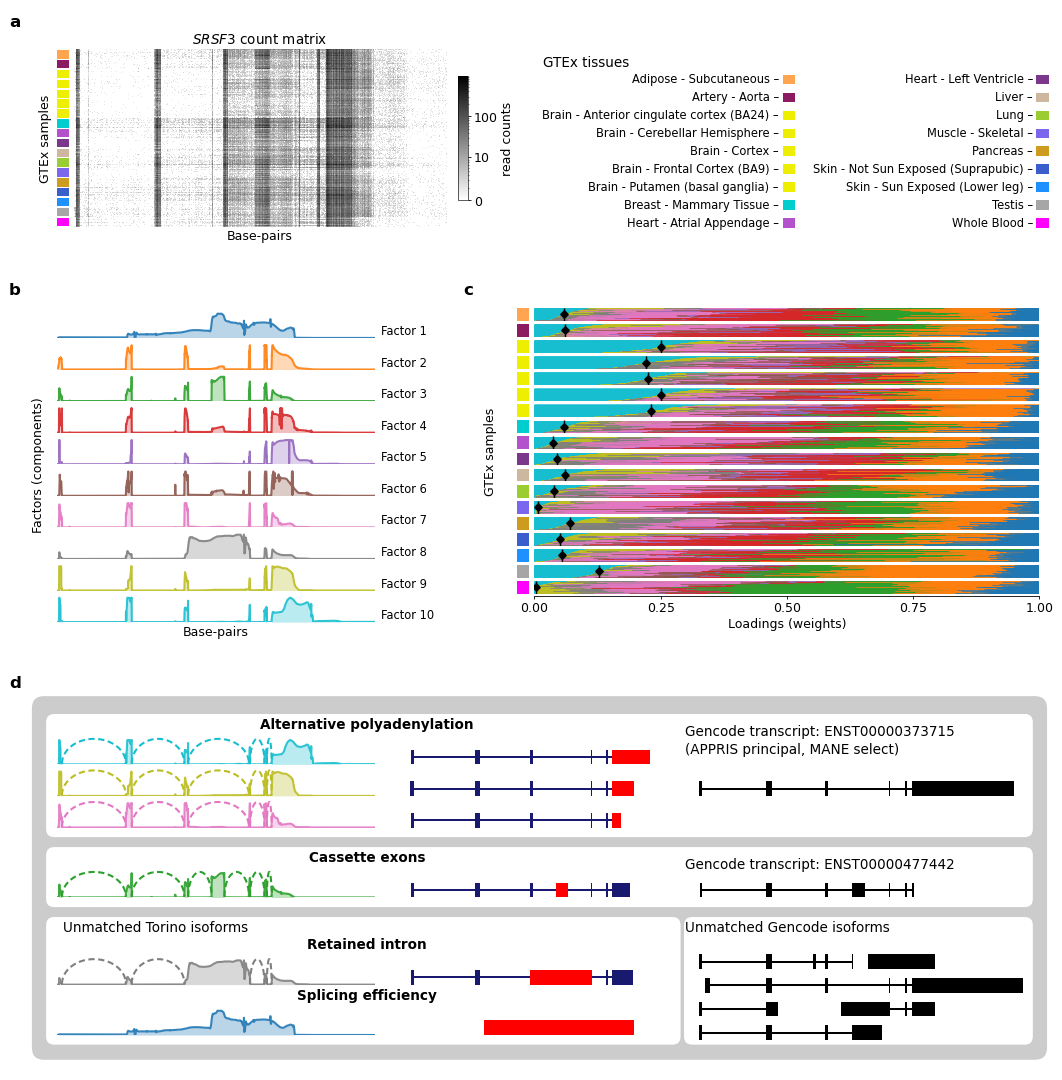

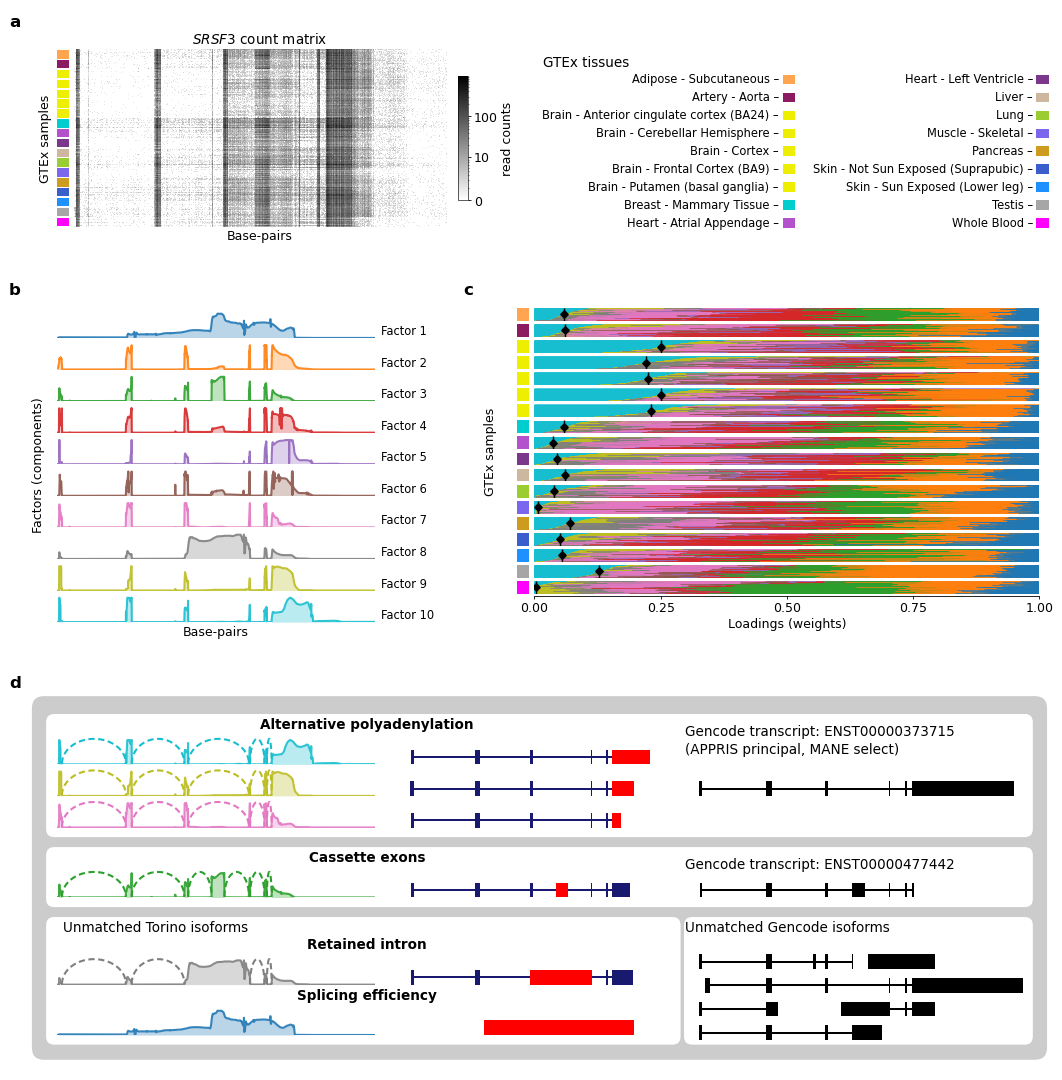

In [10]:
# ── The canvas plan, in millimetres from the top-left corner ───────────
#   Panel A is deliberately narrow: the tissue key sits beside it, and the
#   factor tracks of panels B and D share one column, so the whole figure
#   hangs off a single vertical rule at MARGIN_L.
A_Y, A_H = 8.5, 30.0          # counts heatmap
A_HEAT_W = 63.0
A_CBAR_W = 1.8
LEG_X = 92.0                  # tissue key, right of panel A
B_Y = 52.0                    # factor tracks / loadings row
C_X_LABEL = 83.0              # panel C's rotated y-label
C_X_CHIP = 87.5               # tissue colour chips
C_BAR_X = 90.5
C_BAR_W = 85.5
D_Y = 118.0                   # top of the grey container
MARGIN_R = 2.0


def build_figure():
    fig = plt.figure(figsize=(FIG_W_MM * MM, FIG_H_MM * MM))

    def rect(x, y, w, h):
        """(x, y) is the top-left corner, in mm from the top-left of the page."""
        return [x / FIG_W_MM, (FIG_H_MM - y - h) / FIG_H_MM,
                w / FIG_W_MM, h / FIG_H_MM]

    def label(x, y, text):
        fig.text(x / FIG_W_MM, (FIG_H_MM - y) / FIG_H_MM, text,
                 fontsize=FS_PANEL, fontweight='bold', va='top', ha='left')

    # ── Geometry shared between panels B and D ─────────────────────────
    d_x, d_w = D_X0 * FIG_W_MM, D_W * FIG_W_MM
    trk_x = d_x + D_COL_TRACK[0] * d_w
    trk_w = (D_COL_TRACK[1] - D_COL_TRACK[0]) * d_w
    row_h = D_ROW_H * d_w
    _, d_total = d_vertical_plan()
    d_h = d_total * d_w

    # ── Panel A: counts heatmap + tissue key ───────────────────────────
    heat_x = trk_x + 2.8
    cbar_x = heat_x + A_HEAT_W + 2.0
    ax_A_side = fig.add_axes(rect(trk_x, A_Y, 2.0, A_H))
    ax_A_heat = fig.add_axes(rect(heat_x, A_Y, A_HEAT_W, A_H))
    cax_A = fig.add_axes(rect(cbar_x, A_Y + A_H * 0.15, A_CBAR_W, A_H * 0.70))
    panel_A(ax_A_side, ax_A_heat, cax_A)

    ax_leg = fig.add_axes(rect(LEG_X, A_Y, FIG_W_MM - MARGIN_R - LEG_X, A_H))
    panel_legend(ax_leg)

    # ── Panel B: factor tracks, directly above panel D's tracks ────────
    axes_B = [fig.add_axes(rect(trk_x, B_Y + i * row_h, trk_w, row_h))
              for i in range(K_factors)]
    panel_B(axes_B)
    fig.text((trk_x - 3.2) / FIG_W_MM,
             (FIG_H_MM - B_Y - K_factors * row_h / 2) / FIG_H_MM,
             'Factors (components)', rotation=90, ha='center', va='center',
             fontsize=FS_BASE)

    # ── Panel C: stacked loadings, same vertical extent as B ───────────
    c_h = K_factors * row_h
    c_axis_h = 4.5
    tissue_h = (c_h - c_axis_h) / n_tissues_h
    axes_C_bars, axes_C_blocks = [], []
    for j in range(n_tissues_h):
        y = B_Y + j * tissue_h
        pad = tissue_h * 0.10
        axes_C_blocks.append(fig.add_axes(rect(C_X_CHIP, y + pad, 2.0, tissue_h - 2 * pad)))
        axes_C_bars.append(fig.add_axes(rect(C_BAR_X, y + pad, C_BAR_W, tissue_h - 2 * pad)))
    ax_C_axis = fig.add_axes(rect(C_BAR_X, B_Y + c_h - c_axis_h, C_BAR_W, 1e-4))
    panel_C(axes_C_bars, axes_C_blocks, ax_C_axis)
    fig.text(C_X_LABEL / FIG_W_MM,
             (FIG_H_MM - B_Y - (c_h - c_axis_h) / 2) / FIG_H_MM,
             'GTEx samples', rotation=90, ha='center', va='center', fontsize=FS_BASE)

    # ── Panel D ────────────────────────────────────────────────────────
    panel_D(fig, D_X0, (FIG_H_MM - D_Y - d_h) / FIG_H_MM, D_W)

    # ── Panel letters ──────────────────────────────────────────────────
    label(1.5, 2.5, PANEL_LETTERS[0])
    label(1.5, B_Y - 4.0, PANEL_LETTERS[1])
    label(C_X_LABEL - 4.5, B_Y - 4.0, PANEL_LETTERS[2])
    label(1.5, D_Y - 3.5, PANEL_LETTERS[3])
    return fig

fig = build_figure()
fig

## Export

In [11]:
fig.savefig('Figure1_publication.pdf')
fig.savefig('Figure1_publication.png', dpi=400)
print('Saved Figure1_publication.pdf and Figure1_publication.png '
      f'({FIG_W_MM:.0f} x {FIG_H_MM:.0f} mm)')

Saved Figure1_publication.pdf and Figure1_publication.png (180 x 183 mm)


## Notes and deviations

**Faithful to `Fig1_alt.png`:**

* Panel d colours -- factor tracks are `tab10[factor - 1]` at `alpha=0.9` (fill
  `alpha=0.3`); Torino exons `midnightblue`; the distinguishing exon of each
  isoform `red`; Gencode models `black` (the exploratory notebook used
  `dimgray`); container `#cccccc` on white boxes.
* Panel d scale -- the factor-track, Torino-model and Gencode-model columns
  share one bp-per-unit scale, so features are directly comparable in size
  across the three columns even though each column has its own origin.
* Isoform models sit at the *bottom* of their row, level with the baseline of
  the factor track beside them.
* Panel a's tissue strip uses equal-sized blocks, as in the reference, so it
  does **not** align with the heatmap rows -- it reads as a key. Set
  `SIDEBAR_PROPORTIONAL = True` to size the blocks by sample count instead.

**Deliberate departures:**

* The decorative blue gradient "zoom" triangles that linked panels in the
  Inkscape file are not reproduced.
* Legend labels use the exact `tissues_display` strings; `Fig1_alt.png` shows
  hand-edited variants with typos ("cinculate", "Skin Not Sun Exposed").
* The `Splicing efficiency` red bar is drawn at its true coordinates
  (chr6:36,597,113-36,602,770); in `Fig1_alt.png` that one bar was stretched by
  hand and sits slightly wide of the other models.
* Panel letters are bold lower-case, per Nature house style. Set
  `PANEL_LETTERS = 'ABCD'` for journals that want upper case.

**Export note.** Save with the default (`standard`) bbox, never
`bbox_inches='tight'`: panel d's container and white boxes are figure-level
patches, invisible to the tight-bbox pass, so a tight save crops them away --
and it would also throw away the exact 180 mm page width.

**Performance note.** All ~2,000 x 10 loading segments of a tissue go into a
single rasterised `LineCollection`. Splitting them per factor produces ~180
separate rasterised groups, which makes the PDF export allocate a full-figure
raster buffer per group and kills the kernel.

**Main tuning knobs**

* Canvas and type: `FIG_W_MM`, `FIG_H_MM`, the `FS_*` sizes, `PANEL_LETTERS`.
* Shared track look: `TRACK_YMAX`, `TRACK_LW` (panels b and d together).
* Panel d internals: `D_ROW_H`, `D_TITLE_H`, `D_COL_*`, `D_ARC_APEX`, and
  `D_X0` / `D_W` for where the container sits on the page.
* Page plan: the mm constants above `build_figure` (`A_Y`, `A_H`, `A_HEAT_W`,
  `LEG_X`, `B_Y`, `C_BAR_X`, `C_BAR_W`, `D_Y`).
